# Flood DEM Sensitivity: SRTM vs Copernicus GLO-30 vs ALOS AW3D30

**Studi kasus:** Kota Semarang dan Kabupaten Demak.
**Kerangka:** eksperimen terkontrol untuk mengukur sensitivitas hasil *flood susceptibility mapping* terhadap **sumber produk elevasi**.

Notebook ini adalah implementasi langsung desain kunci proposal Metodologi Penelitian, dibangun sebagai kelanjutan (*sambung tangan*) dari notebook artikel SMDS (`Flood Susceptibility Mapping Notebook.ipynb`). Yang **dikunci identik** di semua konfigurasi:

1. flood inventory Sentinel-1 (dibentuk satu kali),
2. prediktor non-DEM,
3. wilayah penelitian (AOI),
4. prosedur sampling + seed,
5. pembagian data latih-uji + seed,
6. algoritme dan parameter Random Forest (sklearn untuk evaluasi, GEE untuk peta spasial).

Yang **diubah (faktor perlakuan)**: hanya sumber produk elevasi — SRTM, Copernicus DEM GLO-30, ALOS AW3D30 — dari mana prediktor topografi (elevasi, slope, aspect) dihitung.

**Output:**

- 3 peta probabilitas *flood susceptibility* (satu per konfigurasi DEM),
- tabel perbandingan metrik performa (ROC-AUC, accuracy, precision, recall, F1),
- peta dan ringkasan perubahan probabilitas (sensitivitas spasial),
- kesesuaian kelas dan matriks perpindahan kelas antarproduk,
- stratifikasi sensitivitas berdasarkan kelas tutupan lahan ESA WorldCover.

## 0. Dataset yang dipakai

- Sentinel-1 GRD: `COPERNICUS/S1_GRD` — pembentukan *flood inventory* (change detection backscatter).
- Sentinel-2 SR: `COPERNICUS/S2_SR_HARMONIZED` — NDVI, NDWI, MNDWI, NDBI.
- SRTM: `USGS/SRTMGL1_003` — **perlakuan elevasi 1**.
- Copernicus DEM GLO-30: `COPERNICUS/DEM/GLO30` — **perlakuan elevasi 2**.
- ALOS AW3D30: `JAXA/ALOS/AW3D30/V4_1` — **perlakuan elevasi 3**.
- CHIRPS Daily: `UCSB-CHG/CHIRPS/DAILY` — curah hujan antecedent 7 dan 30 hari.
- ESA WorldCover 2021: `ESA/WorldCover/v200` — stratifikasi tutupan lahan.
- MERIT Hydro: `MERIT/Hydro/v1_0_1` — HAND, upstream drainage area, river width.
- JRC Global Surface Water: `JRC/GSW1_4/GlobalSurfaceWater` — masking perairan permanen.

**Catatan desain:** set prediktor di notebook ini mengikuti set baseline artikel SMDS sebagai titik awal. Daftar final prediktor belum dikunci di proposal (menunggu audit literatur); bila nanti berubah, cukup modifikasi bagian *prediktor non-DEM* dan *DEM-derived predictors* — kerangka eksperimen tidak berubah.

## 1. Import library

In [1]:
# Kaggle/Colab: pastikan paket tersedia (diabaikan jika sudah terpasang).
!pip install -q earthengine-api geemap

In [2]:
import os
import time
import math
import warnings
warnings.filterwarnings('ignore')

# Direktori output: Colab Drive jika berjalan di Colab, fallback ke direktori kerja.
# PENTING: jangan import google.colab di Kaggle, karena geemap mendeteksi
# keberadaan modul 'google.colab' sebagai tanda lingkungan Colab dan akan
# mencoba mengambil secret (yang gagal/timeout di luar Colab).
if os.path.isdir('/content'):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        OUTPUT_DIR = '/content/drive/MyDrive/GEE_DEM_Sensitivity_Semarang_Demak'
    except Exception:
        OUTPUT_DIR = 'outputs_dem_sensitivity'
else:
    OUTPUT_DIR = 'outputs_dem_sensitivity'
os.makedirs(OUTPUT_DIR, exist_ok=True)

import ee
import geemap

# Kaggle: geemap mendeteksi modul 'google.colab' sebagai lingkungan Colab lalu
# mencoba mengambil secret (timeout di luar Colab). Patch get_env_var agar
# HANYA membaca environment variable biasa. TIDAK ada GOOGLE_MAPS_API_KEY yang
# di-set, sehingga geemap otomatis memakai basemap OpenStreetMap/Esri (tanpa key).
try:
    import os as _os2
    import geemap.coreutils as _gcu
    _gcu.get_env_var = lambda key, *a, **k: _os2.environ.get(key)
    if hasattr(_gcu, "get_google_maps_api_key"):
        _gcu.get_google_maps_api_key = lambda key="GOOGLE_MAPS_API_KEY", *a, **k: _os2.environ.get(key)
    print("geemap coreutils dipatch (mode tanpa Google Maps API key).")
except Exception as _e:
    print("Patch geemap dilewati:", _e)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Output dir:', OUTPUT_DIR)

geemap coreutils dipatch (mode tanpa Google Maps API key).
Output dir: outputs_dem_sensitivity


## 2. Autentikasi Google Earth Engine

In [3]:
# =========================================================
# Autentikasi Google Earth Engine.
# Cara utama: Service Account key JSON (TANPA login popup setiap run).
#   1. Buat key: https://console.cloud.google.com/iam-admin/serviceaccounts
#      -> pilih project -> Keys -> Add key -> JSON.
#   2. Beri role 'Service Usage Consumer' dan daftarkan akun Earth Engine
#      (https://code.earthengine.google.com/register) dengan project yang sama.
#   3. Simpan file JSON di Drive folder
#      GEE_DEM_Sensitivity_Semarang_Demak/ dengan nama gee-service-account.json
# Jika key tidak ditemukan, fallback ke ee.Authenticate() interaktif.
# =========================================================
EE_PROJECT = "ee-irfan-banjir-2026"

import os as _os, json as _json, base64 as _b64

_service_email, _key_path = None, None

def _try_use_key(path):
    global _service_email, _key_path
    try:
        with open(path, 'r', encoding='utf-8') as fh:
            info = _json.load(fh)
        if info.get('type') != 'service_account':
            print('Bukan service account key:', path)
            return False
        creds = ee.ServiceAccountCredentials(info['client_email'], path)
        ee.Initialize(credentials=creds, project=(info.get('project_id') or EE_PROJECT or None))
        _service_email, _key_path = info['client_email'], path
        return True
    except Exception as e:
        print('Key gagal dipakai (%s): %s' % (path, e))
        return False

_key_candidates = [
    '/kaggle/input/datasets/nxtirfan/gee-service-account-credential/gee-service-account.json',
    '/kaggle/input/gee-service-account-credential/gee-service-account.json',
    '/content/drive/MyDrive/GEE_DEM_Sensitivity_Semarang_Demak/gee-service-account.json',
    '/content/gee-service-account.json',
    '/kaggle/working/gee-service-account.json',
    'gee-service-account.json',
]

# Kaggle: cari file kredensial secara rekursif di seluruh /kaggle/input
# (nama folder mount dapat berbeda dari dugaan).
try:
    import glob as _glob
    if _os.path.isdir('/kaggle/input'):
        print('/kaggle/input berisi:', _os.listdir('/kaggle/input'))
        _found = _glob.glob('/kaggle/input/**/*service-account*.json', recursive=True)
        print('Kandidat kredensial ditemukan via glob:', _found)
        for _f in _found:
            _key_candidates.insert(0, _f)
except Exception as _e:
    print('Glob /kaggle/input dilewati:', _e)
if _os.environ.get('GOOGLE_APPLICATION_CREDENTIALS'):
    _key_candidates.insert(0, _os.environ['GOOGLE_APPLICATION_CREDENTIALS'])

# Kaggle Secrets (isi JSON sebagai string)
try:
    from kaggle_secrets import UserSecretsClient
    _sec = UserSecretsClient().get_secret("GEE_SERVICE_ACCOUNT_JSON")
    if _sec and 'service_account' in _sec:
        try:
            _sec = _b64.b64decode(_sec).decode('utf-8')
        except Exception:
            pass
        _p = '/kaggle/working/gee-service-account.json'
        with open(_p, 'w', encoding='utf-8') as fh:
            fh.write(_sec)
        _key_candidates.insert(0, _p)
except Exception:
    pass

_initialized = False
for _p in _key_candidates:
    if _p and _os.path.exists(_p):
        _initialized = _try_use_key(_p)
        if _initialized:
            break

if not _initialized:
    print('Service account key tidak ditemukan/gagal. Fallback ke login interaktif...')
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT) if EE_PROJECT else ee.Initialize()

if _service_email:
    print('GEE siap via service account:', _service_email)
else:
    print('GEE siap via login interaktif.')

/kaggle/input berisi: ['datasets']
Kandidat kredensial ditemukan via glob: ['/kaggle/input/datasets/nxtirfan/gee-service-account-credential/gee-service-account.json']
GEE siap via service account: nxtirfan@ee-irfan-banjir-2026.iam.gserviceaccount.com


## 3. Parameter wilayah, tanggal, dan eksperimen

In [4]:
# =========================================================
# PARAMETER WILAYAH
# =========================================================
# ROI mengikuti baseline: Kota Semarang + Kabupaten Demak (FAO GAUL level 2).
ROI_MODE = 'SEMDEMAK_ONLY'
SURROUNDING_RECTANGLE = [109.95, -7.45, 111.05, -6.65]  # [lon_min, lat_min, lon_max, lat_max]

wilayah_indonesia = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM0_NAME', 'Indonesia'))

if ROI_MODE == 'SEMDEMAK_ONLY':
    wanted_names_primary = ['Kota Semarang', 'Demak']
    semarang_demak = wilayah_indonesia.filter(ee.Filter.inList('ADM2_NAME', wanted_names_primary))
    if semarang_demak.size().getInfo() < 2:
        print('Peringatan: filter primary belum menemukan dua wilayah. Fallback nama Semarang + Demak.')
        semarang_demak = wilayah_indonesia.filter(ee.Filter.inList('ADM2_NAME', ['Semarang', 'Demak']))
    print('Wilayah administratif terpilih:', semarang_demak.aggregate_array('ADM2_NAME').getInfo())
    roi = semarang_demak.geometry()
else:
    roi = ee.Geometry.Rectangle(SURROUNDING_RECTANGLE)
    semarang_demak = ee.FeatureCollection([ee.Feature(roi, {'ADM2_NAME': 'Semarang-Demak surrounding rectangle'})])

# Kejadian banjir: sama dengan baseline (banjir Jawa Tengah / Demak II, Maret 2024).
BEFORE_START = '2024-02-25'
BEFORE_END   = '2024-03-12'
AFTER_START  = '2024-03-15'
AFTER_END    = '2024-03-31'

# Komposit Sentinel-2 untuk prediktor permukaan (periode normal, hindari data leakage).
S2_START = '2023-06-01'
S2_END   = '2023-10-31'

# Parameter label banjir Sentinel-1 (identik baseline).
S1_POLARIZATION = 'VH'
S1_RATIO_THRESHOLD = 1.25
AFTER_DB_THRESHOLD = -18
SLOPE_MAX_FOR_FLOOD = 5
MIN_CONNECTED_PIXELS = 8

# Sampling (identik untuk semua konfigurasi).
SAMPLE_PER_CLASS_TARGET = 3000
AUTO_BALANCE_SAMPLE = True
SAMPLE_SCALE = 30
TILE_SCALE = 8

RIVER_UPA_THRESHOLD = 10  # km^2, threshold upstream area untuk dist_river

MAP_CENTER = [-7.05, 110.45]
MAP_ZOOM = 10

# =========================================================
# KONFIGURASI EKSPERIMEN (desain kunci proposal)
# =========================================================
# Satu-satunya faktor yang berubah antarperlakuan: SUMBER PRODUK ELEVASI.
DEM_CONFIGS = {
    'srtm':   {'label': 'SRTM',              'asset': 'USGS/SRTMGL1_003',      'type': 'image',      'band': 'elevation'},
    'glo30':  {'label': 'Copernicus GLO-30', 'asset': 'COPERNICUS/DEM/GLO30',  'type': 'collection', 'band': 'DEM'},
    'aw3d30': {'label': 'ALOS AW3D30',       'asset': 'JAXA/ALOS/AW3D30/V4_1', 'type': 'collection', 'band': 'DSM'},
}
DEM_NAMES = list(DEM_CONFIGS.keys())

# Random Forest DIKUNCI (mengikuti baseline artikel SMDS).
RF_SKLEARN = dict(n_estimators=400, min_samples_leaf=2,
                  class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
RF_GEE = dict(numberOfTrees=300, variablesPerSplit=None,
              minLeafPopulation=2, bagFraction=0.7, seed=RANDOM_STATE)

# Klasifikasi 5 kelas kerawanan.
# 'equal_interval'    : batas tetap 0.2 / 0.4 / 0.6 / 0.8 (default). Breaks SAMA untuk
#                       ketiga peta sehingga perbandingan kelas antar-DEM valid.
# 'quantile_reference': batas kuantile dihitung dari peta referensi (SRTM) lalu
#                       diterapkan sama ke ketiga peta.
RISK_CLASS_METHOD = 'equal_interval'

print('Konfigurasi eksperimen:', DEM_NAMES)
print('Kunci: flood inventory, prediktor non-DEM, sampling, split, dan parameter RF identik.')

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


Wilayah administratif terpilih: ['Demak', 'Kota Semarang']
Konfigurasi eksperimen: ['srtm', 'glo30', 'aw3d30']
Kunci: flood inventory, prediktor non-DEM, sampling, split, dan parameter RF identik.


## 4. Fungsi bantu Earth Engine

In [5]:
def db_to_power(img_db):
    # Konversi Sentinel-1 dB ke power scale.
    return ee.Image(10).pow(img_db.divide(10))


def get_s1_median(start, end, roi, orbit_pass=None):
    # Ambil median Sentinel-1 GRD VV/VH untuk periode tertentu.
    col = (ee.ImageCollection('COPERNICUS/S1_GRD')
           .filterBounds(roi)
           .filterDate(start, end)
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
           .select(['VV', 'VH']))
    if orbit_pass is not None:
        col = col.filter(ee.Filter.eq('orbitProperties_pass', orbit_pass))
    return col.median().clip(roi)


def mask_s2_clouds(img):
    # Mask awan sederhana Sentinel-2 SR memakai QA60.
    qa = img.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(
        qa.bitwiseAnd(cirrus_bit_mask).eq(0)
    )
    return img.updateMask(mask).divide(10000)


def add_lon_lat(feature):
    coords = feature.geometry().coordinates()
    return feature.set({'lon': coords.get(0), 'lat': coords.get(1)})


def count_binary_pixels(binary_img, band_name, roi, scale=30, tileScale=8):
    hist = (binary_img.select(band_name)
            .reduceRegion(
                reducer=ee.Reducer.frequencyHistogram(),
                geometry=roi,
                scale=scale,
                maxPixels=1e13,
                tileScale=tileScale
            )
            .get(band_name)
            .getInfo())
    hist = hist or {}
    n0 = int(float(hist.get('0', hist.get(0, 0))))
    n1 = int(float(hist.get('1', hist.get(1, 0))))
    return n0, n1, hist


def safe_add_legend(MapObj, title, legend_dict):
    try:
        MapObj.add_legend(title=title, legend_dict=legend_dict)
    except Exception as e:
        print(f'Legend tidak bisa ditambahkan otomatis: {title} | {e}')


def save_thumb(image, vis_params, region, filename, dimensions=1600, max_retries=4, base_delay=5):
    # Simpan citra Earth Engine sebagai PNG statis tanpa geemap.Map
    # (menghindari kebutuhan Google Maps API key di Kaggle).
    vis_img = image.visualize(**vis_params)
    current_dim = dimensions
    last_error = None
    for attempt in range(max_retries):
        try:
            url = vis_img.getThumbURL({'region': region, 'dimensions': current_dim, 'format': 'png'})
            r = requests.get(url, timeout=180)
            r.raise_for_status()
            img = Image.open(BytesIO(r.content)).convert('RGB')
            path = os.path.join(OUTPUT_DIR, filename)
            img.save(path)
            print('Thumbnail tersimpan:', path)
            return img
        except Exception as e:
            last_error = e
            current_dim = max(int(current_dim * 0.75), 600)
            print(f'Thumbnail gagal (percobaan {attempt + 1}/{max_retries}), coba {current_dim}px: {e}')
            time.sleep(base_delay)
    print('Gagal membuat thumbnail:', filename, '|', last_error)
    return None


def safe_add_layer_control(MapObj):
    try:
        MapObj.add_layer_control()
    except Exception:
        try:
            MapObj.addLayerControl()
        except Exception:
            pass


FLOOD_VIS = {'min': 0, 'max': 1, 'palette': ['#ff00ff']}
PERM_WATER_VIS = {'min': 0, 'max': 1, 'palette': ['#0047ab']}
PROB_VIS = {'min': 0, 'max': 1, 'palette': ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000']}
DELTA_VIS = {'min': 0, 'max': 0.5, 'palette': ['#ffffbf', '#fd8d3c', '#7f0000']}
RISK_VIS = {'min': 1, 'max': 5, 'palette': ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000']}
ELEV_DIFF_VIS = {'min': -5, 'max': 5, 'palette': ['#2c7bb6', '#ffffbf', '#d7191c']}

flood_legend = {
    'Proxy flood label': '#ff00ff',
    'Permanent water mask': '#0047ab'
}
risk_legend = {
    'Very low / Sangat rendah': '#1a9850',
    'Low / Rendah': '#91cf60',
    'Moderate / Sedang': '#ffffbf',
    'High / Tinggi': '#f16913',
    'Very high / Sangat tinggi': '#7f0000'
}
print('Fungsi bantu siap.')

Fungsi bantu siap.


## 5. Flood inventory Sentinel-1 (dikunci)

Flood inventory dibentuk **satu kali** dengan prosedur baseline artikel SMDS, lalu dipakai identik pada ketiga eksperimen. Dengan demikian label tidak menjadi sumber variasi antarperlakuan.

Catatan: Masking slope pada prosedur baseline memakai SRTM. Karena inventory harus identik, keputusan ini diterapkan sama untuk ketiga konfigurasi dan dilaporkan sebagai keterbatasan metodologis.

In [6]:
s1_before = get_s1_median(BEFORE_START, BEFORE_END, roi)
s1_after = get_s1_median(AFTER_START, AFTER_END, roi)

before_pol_db = s1_before.select(S1_POLARIZATION)
after_pol_db = s1_after.select(S1_POLARIZATION)

before_pol_power = db_to_power(before_pol_db)
after_pol_power = db_to_power(after_pol_db)

# Jika nilai setelah banjir turun tajam, rasio before/after menjadi besar.
s1_ratio = before_pol_power.divide(after_pol_power).rename('s1_ratio')
s1_db_change = after_pol_db.subtract(before_pol_db).rename('s1_db_change')

# Masking slope mengikuti prosedur baseline (memakai SRTM) — dikonsistenkan
# untuk semua konfigurasi karena inventory harus identik.
dem_for_label = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(roi)
slope_for_label = ee.Terrain.slope(dem_for_label).rename('slope')

# Mask air permanen agar laut, sungai, waduk, tambak permanen tidak dianggap banjir.
jrc_water = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').clip(roi)
permanent_water = jrc_water.gte(80).rename('permanent_water')

# Deteksi banjir awal.
flood_raw = (s1_ratio.gt(S1_RATIO_THRESHOLD)
             .And(after_pol_db.lt(AFTER_DB_THRESHOLD))
             .And(permanent_water.Not())
             .And(slope_for_label.lt(SLOPE_MAX_FOR_FLOOD)))

# Filter noise area kecil.
flood_connected = (flood_raw.selfMask()
                   .connectedPixelCount(100, True)
                   .gte(MIN_CONNECTED_PIXELS)
                   .unmask(0)
                   .rename('flood'))

# Label final: 1 = indikasi genangan, 0 = tidak tergenang.
flood_label = flood_connected.rename('flood').clip(roi)

print('Flood inventory selesai dibuat (dibentuk satu kali, dipakai ketiga eksperimen).')

Flood inventory selesai dibuat (dibentuk satu kali, dipakai ketiga eksperimen).


## 6. Visualisasi label banjir

In [7]:
Map = geemap.Map(center=[MAP_CENTER[0], MAP_CENTER[1]], zoom=MAP_ZOOM)
Map.add_basemap('HYBRID')
Map.centerObject(roi, MAP_ZOOM)
# FAULT-TOLERANT v22: layer tile (getMapId) boleh timeout tanpa menggagalkan run.
try:
    Map.addLayer(permanent_water.selfMask(), PERM_WATER_VIS, 'Permanent water (JRC >= 80)')
    Map.addLayer(flood_label.selfMask(), FLOOD_VIS, 'Proxy flood label (S1)')
    Map.addLayer(s1_ratio, {'min': 0.5, 'max': 3, 'palette': ['#f7fbff', '#c6dbef', '#6baed6', '#fd8d3c', '#e31a1c']}, 'S1 ratio (before/after power)')
except Exception as e:
    print(f'Lapisan peta Map dilewati (tile service timeout, hasil tidak terpengaruh): {e}')
safe_add_legend(Map, 'Legend', flood_legend)
safe_add_layer_control(Map)

# Bonus: figure statis PNG untuk artikel (tanpa mengubah visual utama).
save_thumb(flood_label.selfMask(), FLOOD_VIS, roi, 'fig_flood_label.png')
Map

Thumbnail tersimpan: outputs_dem_sensitivity/fig_flood_label.png


Map(center=[-6.9475803324210075, 110.56793539002611], controls=(WidgetControl(options=['position', 'transparen…

## 7. Prediktor non-DEM (dikunci)

Dibangun sekali, dipakai ulang untuk ketiga konfigurasi. Mengikuti set baseline artikel SMDS: HAND, log-upstream area, river width, jarak ke sungai, jarak ke air permanen, curah hujan antecedent 7/30 hari, indeks spektral Sentinel-2, dan kelas tutupan lahan WorldCover.

In [8]:
ref_proj = ee.Image('USGS/SRTMGL1_003').projection()

# MERIT Hydro.
merit = ee.Image('MERIT/Hydro/v1_0_1').clip(roi)
hand = merit.select('hnd').rename('hand')
upa = merit.select('upa').rename('upa')
upa_log = upa.add(1).log().rename('upa_log')
# Lebar sungai hanya terdefinisi pada piksel sungai; diisi 0 di luar sungai
# agar band ini tidak mengosongkan sampling multi-band (0 = tidak ada sungai).
river_width = merit.select('wth').unmask(0).rename('river_width')

# Aproksimasi jaringan sungai (threshold upstream area).
river_mask = upa.gt(RIVER_UPA_THRESHOLD).rename('river_mask').reproject(crs=ref_proj, scale=30)
dist_river = (river_mask.selfMask()
              .fastDistanceTransform(2048)
              .sqrt()
              .multiply(30)
              .rename('dist_river')
              .unmask(2048 * 30)
              .clip(roi))

# Jarak ke air permanen.
perm_water_30 = permanent_water.rename('perm_water_30').reproject(crs=ref_proj, scale=30)
dist_perm_water = (perm_water_30.selfMask()
                   .fastDistanceTransform(2048)
                   .sqrt()
                   .multiply(30)
                   .rename('dist_perm_water')
                   .unmask(2048 * 30)
                   .clip(roi))

# Curah hujan pra-kejadian dari CHIRPS.
rain_7d = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
           .filterDate(ee.Date(AFTER_START).advance(-7, 'day'), AFTER_START)
           .filterBounds(roi)
           .select('precipitation')
           .sum()
           .rename('rain_7d')
           .clip(roi))

rain_30d = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
            .filterDate(ee.Date(AFTER_START).advance(-30, 'day'), AFTER_START)
            .filterBounds(roi)
            .select('precipitation')
            .sum()
            .rename('rain_30d')
            .clip(roi))

# Sentinel-2 indeks permukaan.
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(roi)
      .filterDate(S2_START, S2_END)
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
      .map(mask_s2_clouds)
      .median()
      .clip(roi))

ndvi = s2.normalizedDifference(['B8', 'B4']).rename('ndvi')
ndwi = s2.normalizedDifference(['B3', 'B8']).rename('ndwi')
mndwi = s2.normalizedDifference(['B3', 'B11']).rename('mndwi')
ndbi = s2.normalizedDifference(['B11', 'B8']).rename('ndbi')

# Tutupan lahan.
landcover = (ee.ImageCollection('ESA/WorldCover/v200')
             .first()
             .select('Map')
             .rename('landcover')
             .clip(roi))

# Stack prediktor non-DEM (DIKUNCI).
fixed_stack = ee.Image.cat([
    hand,
    upa_log,
    river_width,
    dist_river,
    dist_perm_water,
    rain_7d,
    rain_30d,
    ndvi,
    ndwi,
    mndwi,
    ndbi,
    landcover
]).clip(roi)

fixed_bands = fixed_stack.bandNames().getInfo()
print('Prediktor non-DEM (dikunci):')
print(fixed_bands)

Prediktor non-DEM (dikunci):
['hand', 'upa_log', 'river_width', 'dist_river', 'dist_perm_water', 'rain_7d', 'rain_30d', 'ndvi', 'ndwi', 'mndwi', 'ndbi', 'landcover']


## 8. Tiga konfigurasi produk elevasi (faktor perlakuan)

Dari setiap produk dihitung **elevasi, slope, dan aspect** dengan prosedur yang sama (`ee.Terrain`). Nama band diberi sufiks konfigurasi (misal `elevation_glo30`) sehingga ketiga konfigurasi dapat disimpan dalam satu stack dan satu sampel.

Hal yang ditangani secara eksplisit:

1. **Void mask ALOS AW3D30** (band `MSK`: 0 = valid, 1 = void).
2. **Perbedaan acuan vertikal** — SRTM memakai EGM96, Copernicus/AW3D30 memakai EGM2008. Offset rata-rata terhadap SRTM dilaporkan; koreksi opsional via `APPLY_VERTICAL_OFFSET` (default hanya melaporkan).

In [9]:
def load_dem_raw(cfg):
    # Muat DEM sesuai tipe asset (image vs ImageCollection).
    if cfg['type'] == 'image':
        return ee.Image(cfg['asset']).select(cfg['band']).clip(roi)
    return ee.ImageCollection(cfg['asset']).select(cfg['band']).mosaic().clip(roi)


dem_raw = {name: load_dem_raw(cfg) for name, cfg in DEM_CONFIGS.items()}

# 1. Void mask ALOS AW3D30.
# Band MSK menandai valid/void, tetapi polaritasnya berbeda antar versi data.
# Deteksi otomatis: pilih nilai MSK yang mencakup piksel lebih banyak sebagai "valid".
aw3d_msk = ee.ImageCollection(DEM_CONFIGS['aw3d30']['asset']).select('MSK').mosaic().clip(roi)
_msk_area = ee.Image.pixelArea().addBands(aw3d_msk.rename('msk'))
_msk_stats = _msk_area.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='msk'),
    geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
).getInfo()
_msk_rows = {int(g['msk']): g['sum'] for g in _msk_stats.get('groups', [])}
print('Luas per nilai MSK AW3D30 (m^2):', _msk_rows)
if _msk_rows:
    _valid_value = max(_msk_rows, key=_msk_rows.get)
else:
    _valid_value = 0
print('Nilai MSK dianggap valid:', _valid_value)
dem_raw['aw3d30'] = dem_raw['aw3d30'].updateMask(aw3d_msk.eq(_valid_value))

# 2. Grid analisis yang sama untuk ketiga DEM (meter, UTM 49S, 30 m).
# Hasil biseksi diagnostik: slope dari citra mosaic tanpa proyeksi baku
# menghasilkan citra kosong. Reproject ke grid analisis memaksa ketiganya
# berbagi grid identik sekaligus memperbaiki terrain ops.
ANALYSIS_CRS = 'EPSG:32749'
ANALYSIS_SCALE = 30
for _name in DEM_NAMES:
    dem_raw[_name] = dem_raw[_name].reproject(crs=ANALYSIS_CRS, scale=ANALYSIS_SCALE).clip(roi)
print('Grid analisis:', ANALYSIS_CRS, ANALYSIS_SCALE, 'm (identik untuk ketiga DEM)')

# 2. Offset vertikal vs SRTM (EGM96 vs EGM2008) — kritis pada dataran pesisir rendah.
APPLY_VERTICAL_OFFSET = False
print('Offset vertikal rata-rata terhadap SRTM (m):')
for name in ['glo30', 'aw3d30']:
    diff = dem_raw[name].subtract(dem_raw['srtm']).rename('d')
    off = diff.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).get('d').getInfo()
    print(f'  {name}: {off}')
    if APPLY_VERTICAL_OFFSET and off is not None:
        dem_raw[name] = dem_raw[name].subtract(ee.Number(off))

# Prediktor topografi per konfigurasi (prosedur identik).
# Penanganan terrain v21 (revisi reviewer: encoding sirkular aspect):
# - aspect adalah variabel SIRKULAR (0 = 360); sebagai angka linear, 10 dan 350
#   tampak jauh padahal berdekatan. Karena itu aspect dienkode sebagai
#   sin/cos dari sudut radian: aspect_sin, aspect_cos.
# - ee.Terrain.aspect ter-mask pada piksel datar (slope = 0); sin/cos dari
#   piksel datar diisi 0 (netral — titik (0,0) tak berkorespondensi dengan arah
#   mana pun), dan statusnya dicatat eksplisit via aspect_valid = (slope > 0).
#   Kedataran tetap tertangkap oleh slope = 0. Perlakuan identik ketiga DEM.
# - river_width (MERIT wth) hanya terdefinisi di piksel sungai -> 0 = tidak
#   ada sungai yang dipetakan (makna substantif, bukan imputasi buta).
dem_pred_stacks = {}
for name in DEM_NAMES:
    elev = dem_raw[name].rename(f'elevation_{name}')
    slp = ee.Terrain.slope(dem_raw[name]).rename(f'slope_{name}')
    _asp_raw = ee.Terrain.aspect(dem_raw[name])
    _asp_rad = _asp_raw.multiply(3.141592653589793 / 180.0)
    asp_sin = _asp_rad.sin().unmask(0).rename(f'aspect_sin_{name}')
    asp_cos = _asp_rad.cos().unmask(0).rename(f'aspect_cos_{name}')
    asp_valid = slp.gt(0).rename(f'aspect_valid_{name}')
    dem_pred_stacks[name] = ee.Image.cat(
        [elev, slp, asp_sin, asp_cos, asp_valid]).clip(roi)

def dem_cols(name):
    return [f'elevation_{name}', f'slope_{name}',
            f'aspect_sin_{name}', f'aspect_cos_{name}', f'aspect_valid_{name}']

dem_stack_all = ee.Image.cat([dem_pred_stacks[name] for name in DEM_NAMES])
# Seluruh stack (fixed + DEM) disatukan pada grid analisis UTM 30 m agar
# ekstraksi multi-band tidak kehilangan titik akibat beda proyeksi antarband.
predictor_stack_all = (ee.Image.cat([fixed_stack, dem_stack_all])
                       .reproject(crs=ANALYSIS_CRS, scale=ANALYSIS_SCALE)
                       .clip(roi))
predictor_bands_all = predictor_stack_all.bandNames().getInfo()
print('Total band prediktor:', len(predictor_bands_all))
print(predictor_bands_all)

Luas per nilai MSK AW3D30 (m^2): {0: 1292843989.3590233, 3: 1439923.2405385938, 48: 10068551.12174838}
Nilai MSK dianggap valid: 0
Grid analisis: EPSG:32749 30 m (identik untuk ketiga DEM)
Offset vertikal rata-rata terhadap SRTM (m):
  glo30: -1.5601385335339433
  aw3d30: 0.39494527631611825
Total band prediktor: 27
['hand', 'upa_log', 'river_width', 'dist_river', 'dist_perm_water', 'rain_7d', 'rain_30d', 'ndvi', 'ndwi', 'mndwi', 'ndbi', 'landcover', 'elevation_srtm', 'slope_srtm', 'aspect_sin_srtm', 'aspect_cos_srtm', 'aspect_valid_srtm', 'elevation_glo30', 'slope_glo30', 'aspect_sin_glo30', 'aspect_cos_glo30', 'aspect_valid_glo30', 'elevation_aw3d30', 'slope_aw3d30', 'aspect_sin_aw3d30', 'aspect_cos_aw3d30', 'aspect_valid_aw3d30']


## 9. Perbandingan karakteristik produk elevasi

Menjawab RM/Tujuan 1: seberapa berbeda parameter topografi yang dihasilkan ketiga produk di wilayah penelitian.

In [10]:
def reduce_stats(img, band):
    stats = img.select(band).reduceRegion(
        reducer=(ee.Reducer.percentile([5, 25, 50, 75, 95])
                 .combine(ee.Reducer.mean(), sharedInputs=True)
                 .combine(ee.Reducer.stdDev(), sharedInputs=True)),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).getInfo()
    return stats

rows = []
for name in DEM_NAMES:
    for param in ['elevation', 'slope']:
        stats = reduce_stats(dem_pred_stacks[name], f'{param}_{name}')
        stats_clean = {k: float(v) for k, v in stats.items() if v is not None}
        rows.append({
            'config': name, 'parameter': param,
            **stats_clean
        })
dem_stats_df = pd.DataFrame(rows)
dem_stats_df.to_csv(os.path.join(OUTPUT_DIR, 'dem_stats.csv'), index=False)
display(dem_stats_df)

# Peta selisih elevasi antarproduk (pairwise).
elev_diff = {}
for a, b in [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]:
    elev_diff[(a, b)] = (dem_raw[a].subtract(dem_raw[b])
                          .rename(f'elev_diff_{a}_{b}').clip(roi))
print('Peta selisih elevasi siap: srtm-glo30, srtm-aw3d30, glo30-aw3d30.')

,config,parameter,elevation_srtm_mean,elevation_srtm_p25,elevation_srtm_p5,elevation_srtm_p50,elevation_srtm_p75,elevation_srtm_p95,elevation_srtm_stdDev,slope_srtm_mean,...,elevation_aw3d30_p75,elevation_aw3d30_p95,elevation_aw3d30_stdDev,slope_aw3d30_mean,slope_aw3d30_p25,slope_aw3d30_p5,slope_aw3d30_p50,slope_aw3d30_p75,slope_aw3d30_p95,slope_aw3d30_stdDev
0,srtm,elevation,40.622678,4.534043,0.598278,8.496936,24.599112,234.507896,76.087566,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,srtm,slope,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.032079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,glo30,elevation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,glo30,slope,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,aw3d30,elevation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,24.522925,234.480697,76.219385,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,aw3d30,slope,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,3.1282,0.952421,0.0,1.904251,3.430293,10.916895,4.01686


Peta selisih elevasi siap: srtm-glo30, srtm-aw3d30, glo30-aw3d30.


## 10. Sampling identik (seed tetap) - v24 koreksi "sabuk JRC"

Sampler = `stratifiedSample` kuota [3000, 3000] pada **label ter-mask**, `seed=42`,
grid 30 m - identik untuk ketiga DEM.

**Koreksi MET-001 (bias sabuk JRC)**: kode v20-v22 memakai mask
`permanent_water = JRC occ>=80` yang **sparse**; `.Not()` pada piksel no-data
tetap no-data, sehingga kandidat kelas-0 tersaring diam-diam ke sabuk
terpetakan JRC saja (pool 123.616 px = 8,76% dari label=0; elevasi sampel
kelas-0 rata-rata 4,2 m vs 42,7 m se-AOI). **Fix v24**:
`pw_for_sampling = permanent_water.unmask(0)` - no-data diperlakukan bukan
air; pool kembali se-AOI (97,95% dari label=0). Probe piksel di bawah
mencetak ukuran pool kedua mode; audit distribusi sampel tiap band ada di
sel 11b. `SAMPLING_MODE='v22sabuk'` tetap tersedia untuk audit (replika
pola lama).


In [11]:
# =====================================================================
# SAMPLING v24 - KOREKSI MET-001 (bias "sabuk JRC") + probe piksel
# ---------------------------------------------------------------------
# Bug v20-v22: sampling_mask memakai permanent_water = JRC occ>=80 yang
# SPARSE. '.Not()' atas piksel no-data tetap no-data sehingga kandidat
# kelas-0 tersaring diam-diam: pool hanya 123.616 px (8,76% dari label=0),
# yaitu sabuk terpetakan JRC di sekitar pantai/sungai.
# Fix v24: pw_for_sampling = permanent_water.unmask(0) - no-data JRC
# diperlakukan BUKAN air; pool kelas-0 kembali se-AOI (1.382.033 px,
# 97,95%). SAMPLING_MODE='v22sabuk' disediakan untuk audit bias.
# =====================================================================
SAMPLING_MODE = 'v24'  # 'v24' = fix (mode utama) | 'v22sabuk' = replika kode lama

training_image_all = (ee.Image.cat([fixed_stack, dem_stack_all])
                      .addBands(flood_label)
                      .clip(roi))

def _masked_count(mask_img, name):
    # Jumlah piksel yang lolos mask (nilai bandnya 1) pada grid SAMPLE_SCALE.
    tot = ee.Image.constant(1).updateMask(mask_img).rename(name).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SAMPLE_SCALE, maxPixels=1e13, tileScale=TILE_SCALE
    ).get(name).getInfo()
    return int(round(float(tot)))

# Histogram label piksel tersedia di ROI (identik notebook sebelumnya).
try:
    n_nonflood, n_flood, label_hist = count_binary_pixels(
        training_image_all.select('flood'), 'flood', roi,
        scale=SAMPLE_SCALE, tileScale=TILE_SCALE
    )
    print('Histogram label piksel tersedia:', label_hist)
    print('Piksel non-flood tersedia:', n_nonflood)
    print('Piksel flood tersedia    :', n_flood)
except Exception as e:
    print('Gagal menghitung histogram label. Fallback ke target sampling manual.', e)
    n_nonflood, n_flood = SAMPLE_PER_CLASS_TARGET, SAMPLE_PER_CLASS_TARGET

# Probe piksel sampling: bukti mekanisme sabuk vs fix (tidak menghentikan run).
try:
    _pw_dense_probe = permanent_water.unmask(0)
    _n_aoi = _masked_count(ee.Image.constant(1), 'px')
    _n_jrc = _masked_count(jrc_water, 'jrc_valid')
    _n_pw = _masked_count(permanent_water, 'pw')
    _n_l0 = _masked_count(flood_label.eq(0), 'label0')
    _p22 = _masked_count(flood_label.eq(0).And(permanent_water.Not()), 'pool_v22')
    _p24 = _masked_count(flood_label.eq(0).And(_pw_dense_probe.Not()), 'pool_v24')
    print(f'[probe] piksel AOI (grid 30 m): {_n_aoi}')
    print(f'[probe] JRC valid: {_n_jrc} ({100.0 * _n_jrc / max(_n_aoi, 1):.2f}% dari AOI)')
    print(f'[probe] permanent_water (occ>=80 & valid): {_n_pw}')
    print(f'[probe] label=0 total: {_n_l0}')
    print(f'[probe] pool kelas-0 sabuk/v22: {_p22} ({100.0 * _p22 / max(_n_l0, 1):.2f}% label=0)')
    print(f'[probe] pool kelas-0 unmask0/v24: {_p24} ({100.0 * _p24 / max(_n_l0, 1):.2f}% label=0)')
except Exception as e:
    print('[probe] dilewati (tidak menghentikan pipeline):', e)

if AUTO_BALANCE_SAMPLE:
    SAMPLE_PER_CLASS = int(min(SAMPLE_PER_CLASS_TARGET, n_nonflood, n_flood))
    if SAMPLE_PER_CLASS <= 0:
        raise ValueError('Tidak ada piksel flood/non-flood yang cukup. '
                         'Periksa ROI, tanggal banjir, atau threshold Sentinel-1.')
else:
    SAMPLE_PER_CLASS = SAMPLE_PER_CLASS_TARGET
print('Sampel per kelas yang diminta:', SAMPLE_PER_CLASS)

if SAMPLING_MODE == 'v24':
    pw_for_sampling = permanent_water.unmask(0)
    print('Mode sampling v24 (FIX): no-data JRC diperlakukan BUKAN air.')
else:
    pw_for_sampling = permanent_water
    print('Mode sampling v22sabuk (AUDIT BIAS): replika persis kode lama.')

sampling_mask = (flood_label.eq(1)
                 .Or(flood_label.eq(0).And(pw_for_sampling.Not())))
label_for_sampling = flood_label.updateMask(sampling_mask)

locs_stage1 = (label_for_sampling.rename('flood')
               .stratifiedSample(
                   numPoints=SAMPLE_PER_CLASS,
                   classBand='flood',
                   classValues=[0, 1],
                   classPoints=[SAMPLE_PER_CLASS, SAMPLE_PER_CLASS],
                   seed=RANDOM_STATE,
                   scale=SAMPLE_SCALE,
                   geometries=True,
                   tileScale=TILE_SCALE)
               .map(add_lon_lat))
print('Titik tahap-1 (stratifiedSample pada label ter-mask):',
      locs_stage1.size().getInfo())

# Tahap 2: ekstraksi SEMUA prediktor pada lokasi tahap-1 (identik v20-v23).
vals_all = predictor_stack_all.sampleRegions(
    collection=locs_stage1,
    scale=SAMPLE_SCALE,
    tileScale=TILE_SCALE
)
print('Titik tahap-2 (pasca-sampleRegions):', vals_all.size().getInfo())
fc_nonflood = vals_all.filter(ee.Filter.eq('flood', 0))
fc_flood = vals_all.filter(ee.Filter.eq('flood', 1))
print('Jumlah sampel mentah non-flood:', fc_nonflood.size().getInfo())
print('Jumlah sampel mentah flood    :', fc_flood.size().getInfo())

# Buang titik yang memiliki null pada band prediktor mana pun (identik).
sample_fc_raw = (fc_nonflood.merge(fc_flood)
                 .filter(ee.Filter.notNull(predictor_bands_all)))
raw_hist = sample_fc_raw.aggregate_histogram('flood').getInfo() or {}
print('Distribusi sampel awal dari GEE:', raw_hist)

def hist_count(hist, target_class):
    total = 0
    for k, v in hist.items():
        try:
            if int(float(k)) == int(target_class):
                total += int(float(v))
        except Exception:
            pass
    return total

raw_n0 = hist_count(raw_hist, 0)
raw_n1 = hist_count(raw_hist, 1)
if raw_n0 <= 0 or raw_n1 <= 0:
    raise ValueError('Sampel hanya berisi satu kelas (n0=%s, n1=%s). '
                     'Periksa kembali mask/stack prediktor dan flood_label.'
                     % (raw_n0, raw_n1))

if AUTO_BALANCE_SAMPLE:
    SAMPLE_PER_CLASS_FINAL = int(min(SAMPLE_PER_CLASS, raw_n0, raw_n1))
    sample_fc_tmp = sample_fc_raw.randomColumn('rand_balance', RANDOM_STATE)
    nonflood_samples = (sample_fc_tmp.filter(ee.Filter.eq('flood', 0))
                        .sort('rand_balance').limit(SAMPLE_PER_CLASS_FINAL))
    flood_samples = (sample_fc_tmp.filter(ee.Filter.eq('flood', 1))
                     .sort('rand_balance').limit(SAMPLE_PER_CLASS_FINAL))
    sample_fc = (nonflood_samples.merge(flood_samples)
                 .randomColumn('random', RANDOM_STATE).sort('random'))
else:
    SAMPLE_PER_CLASS_FINAL = SAMPLE_PER_CLASS
    sample_fc = sample_fc_raw.randomColumn('random', RANDOM_STATE).sort('random')

final_hist = sample_fc.aggregate_histogram('flood').getInfo() or {}
print('SAMPLE_PER_CLASS final:', SAMPLE_PER_CLASS_FINAL)
print('Distribusi sampel final:', final_hist)
print('Jumlah sampel total:', sample_fc.size().getInfo())


Histogram label piksel tersedia: {'0': 1410980.8431372547, '1': 58573.82352941177}
Piksel non-flood tersedia: 1410980
Piksel flood tersedia    : 58573
[probe] piksel AOI (grid 30 m): 1469555
[probe] JRC valid: 187777 (12.78% dari AOI)
[probe] permanent_water (occ>=80 & valid): 28948
[probe] label=0 total: 1410981
[probe] pool kelas-0 sabuk/v22: 123616 (8.76% label=0)
[probe] pool kelas-0 unmask0/v24: 1382033 (97.95% label=0)
Sampel per kelas yang diminta: 3000
Mode sampling v24 (FIX): no-data JRC diperlakukan BUKAN air.
Titik tahap-1 (stratifiedSample pada label ter-mask): 6000
Titik tahap-2 (pasca-sampleRegions): 5963
Jumlah sampel mentah non-flood: 2978
Jumlah sampel mentah flood    : 2985
Distribusi sampel awal dari GEE: {'0': 2978, '1': 2985}
SAMPLE_PER_CLASS final: 2978
Distribusi sampel final: {'0': 2978, '1': 2978}
Jumlah sampel total: 5956


## 11. Konversi ke DataFrame dan preprocessing

Preprocessing mengikuti baseline artikel SMDS: drop NA, balance ulang kelas, drop kolom non-fitur, dan one-hot encoding untuk landcover.

In [12]:
# DIAGNOSTIK v18 (tidak mengubah pipeline): unduh gabungan TANPA filter
# notNull untuk mengukur fraksi null per band. Menjawab: band mana yang
# menggugurkan titik pada tahap ekstraksi multi-band.
df_diag = geemap.ee_to_df(fc_nonflood.merge(fc_flood))
diag_cols = [c for c in df_diag.columns
             if c not in ('flood', 'random', 'rand_balance', 'lon', 'lat',
                          '.geo', 'system:index')]
null_frac = df_diag[diag_cols].isna().mean().sort_values(ascending=False)
print('Fraksi null per band (TANPA filter notNull), 10 tertinggi:')
print(null_frac.head(10).to_string())
print(f'Baris total pra-filter: {len(df_diag)}')
del df_diag

df = geemap.ee_to_df(sample_fc)
data = df.copy()
data = data.replace([np.inf, -np.inf], np.nan).dropna()
data['flood'] = data['flood'].astype(int)

print('Distribusi label setelah drop NA:')
print(data['flood'].value_counts(dropna=False))

# Balance ulang setelah drop NA agar train/test tetap seimbang.
class_counts = data['flood'].value_counts()
min_class_count = int(class_counts.min())
balanced_parts = []
for cls in sorted(data['flood'].unique()):
    balanced_parts.append(
        data[data['flood'] == cls].sample(n=min_class_count, random_state=RANDOM_STATE)
    )
data = pd.concat(balanced_parts, axis=0).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

drop_cols = ['flood']  # v24: sampling tidak lagi membawa split_base (bridging v23)
if 'split_base' in data.columns:
    drop_cols.append('split_base')
for c in ['system:index', '.geo', 'random', 'rand_balance']:
    if c in data.columns:
        drop_cols.append(c)
# Jangan pakai lon/lat sebagai fitur agar model tidak menghafal lokasi.
for c in ['lon', 'lat']:
    if c in data.columns:
        drop_cols.append(c)

X_all = data.drop(columns=drop_cols)
y = data['flood']

constant_features = [
    c for c in X_all.columns
    if pd.api.types.is_numeric_dtype(X_all[c]) and X_all[c].nunique(dropna=True) <= 1
]
if constant_features:
    print('Fitur konstan dibuang:', constant_features)
    X_all = X_all.drop(columns=constant_features)

if 'landcover' in X_all.columns:
    X_all = pd.get_dummies(X_all, columns=['landcover'], prefix='lc', drop_first=False)

X_all = X_all.apply(pd.to_numeric, errors='coerce')
valid_rows = X_all.notna().all(axis=1)
X_all = X_all.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

if y.nunique() < 2:
    raise ValueError('Data hanya berisi satu kelas setelah preprocessing.')

# Kolom fitur non-DEM (sama untuk semua konfigurasi).
def dem_cols(name):
    return [f'elevation_{name}', f'slope_{name}',
            f'aspect_sin_{name}', f'aspect_cos_{name}', f'aspect_valid_{name}']

fixed_feature_cols = [
    c for c in X_all.columns
    if not (c.startswith('elevation_') or c.startswith('slope_') or c.startswith('aspect_'))
]

print('Total baris:', len(X_all))
print('Jumlah fitur non-DEM:', len(fixed_feature_cols))
print('Contoh kolom landcover dummy:', [c for c in X_all.columns if c.startswith('lc_')][:5])

Fraksi null per band (TANPA filter notNull), 10 tertinggi:
aspect_cos_aw3d30      0.0
aspect_cos_glo30       0.0
aspect_cos_srtm        0.0
aspect_sin_aw3d30      0.0
aspect_sin_glo30       0.0
aspect_sin_srtm        0.0
aspect_valid_aw3d30    0.0
aspect_valid_glo30     0.0
aspect_valid_srtm      0.0
dist_perm_water        0.0
Baris total pra-filter: 5963
Distribusi label setelah drop NA:
flood
0    2978
1    2978
Name: count, dtype: int64
Total baris: 5956
Jumlah fitur non-DEM: 19
Contoh kolom landcover dummy: ['lc_10', 'lc_30', 'lc_40', 'lc_50', 'lc_60']


## 11b. Audit distribusi sampel (checklist reviewer v19)

Sebelum melatih model: (i) pastikan koordinat sampel tersimpan; (ii) ringkas
elevasi/slope per DEM per kelas; (iii) komposisi WorldCover per kelas — untuk
mendeteksi konsentrasi spasial / bias seleksi. Tersimpan sebagai `sample_audit.csv`.

In [13]:
audit_rows = []
topo_bands = [c for c in data.columns if c.startswith(('elevation_', 'slope_'))]
for cls in [0, 1]:
    sub = data[data['flood'] == cls]
    row = {'flood': cls, 'n': int(len(sub)),
           'lon_min': float(sub['lon'].min()), 'lon_max': float(sub['lon'].max()),
           'lat_min': float(sub['lat'].min()), 'lat_max': float(sub['lat'].max())}
    for b in topo_bands:
        row[f'{b}_mean'] = float(sub[b].mean())
        row[f'{b}_std'] = float(sub[b].std())
    lc_frac = sub['landcover'].value_counts(normalize=True)
    for code, frac in lc_frac.items():
        row[f'lc_{int(code)}_frac'] = round(float(frac), 4)
    audit_rows.append(row)
audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(os.path.join(OUTPUT_DIR, 'sample_audit.csv'), index=False)
print('Audit distribusi sampel per kelas:')
print(audit_df.to_string())

Audit distribusi sampel per kelas:
   flood     n     lon_min     lon_max   lat_min   lat_max  elevation_aw3d30_mean  elevation_aw3d30_std  elevation_glo30_mean  elevation_glo30_std  elevation_srtm_mean  elevation_srtm_std  slope_aw3d30_mean  slope_aw3d30_std  slope_glo30_mean  slope_glo30_std  slope_srtm_mean  slope_srtm_std  lc_40_frac  lc_10_frac  lc_50_frac  lc_30_frac  lc_80_frac  lc_90_frac  lc_60_frac  lc_95_frac
0      0  2978  110.275163  110.825741 -7.136890 -6.709741              43.061786             77.943544             41.118723            77.660365            42.668234           77.928527           3.167489          4.176103          2.593386         4.095193         3.076082        3.371043      0.4486      0.2310      0.2075      0.0581      0.0322      0.0158      0.0040      0.0027
1      1  2978  110.294028  110.828435 -7.042028 -6.712706               4.107455              5.736857              1.989657             5.771808             3.248825            6.016175

## 12. Eksperimen Random Forest terkontrol

Ketiga konfigurasi dilatih dengan:

- baris data, urutan data, dan seed yang sama -> train/test split identik,
- parameter RF identik (`RF_SKLEARN`),
- metrik: ROC-AUC, accuracy, precision, recall, F1 (ambang 0.5 dan Youden-optimal).

Tambahan v21 - **validasi spatial 4-fold CV**: 16 blok kuantil lon/lat dibagi
4 fold (seed tetap, fold SAMA untuk ketiga DEM); tiap fold melatih ULANG RF
(parameter identik) pada 12 blok dan menguji pada 4 blok yang ditahan -
tanpa leakage train-test.

Koreksi v22/MET-002: selain pseudo-AUC dari prediksi biner (kolom legacy
`auc_spatial_cv`), AUC spasial dihitung dari **probabilitas**
(`auc_spatial_cv_prob`). Semua prediksi titik uji tersimpan
(`spatial_cv_test_predictions.csv`) sehingga delta-AUC antar-DEM dapat
dibootstrap 1000x: `spatial_cv_delta_auc_bootstrap.csv` - CATATAN:
bootstrap pasangan titik, BELUM blok-spasial (gap ~0,01 antar-DEM belum
layak dijadikan peringkat mutlak).

v24: sampling dikoreksi (sabuk JRC, MET-001) - metrik holdout/CV kini
estimasi se-AOI, bukan hanya dalam domain sabuk.


In [14]:
def get_positive_class_proba(model, X_test):
    proba = model.predict_proba(X_test)
    classes = np.array(model.classes_)
    pos_idx = int(np.where(classes == 1)[0][0])
    return proba[:, pos_idx]


# Split v22/v24: train_test_split acak (test 25%, stratify y, seed 42) -
# identik untuk ketiga konfigurasi. (v23 bridging sempat memakai kolom
# 'split_base' baseline; pada v24 sampling dikoreksi sehingga undian acak
# penuh dipakai sebagai skema resmi. Bila kolom split_base ada, split lama
# otomatis dipakai untuk kompatibilitas.)
if 'split_base' in data.columns:
    _tr_b = (data['split_base'].to_numpy() == 'train')
    print('Split dipakai ulang dari baseline: train=%d test=%d' % (
        int(_tr_b.sum()), int((~_tr_b).sum())))
else:
    _tr_b = None
    print(f'Split v24: train_test_split acak (test 25%, stratify=y, seed={RANDOM_STATE}).')

results = []
for name in DEM_NAMES:
    cols = fixed_feature_cols + dem_cols(name)
    X_cfg = X_all[cols]

    if _tr_b is None:
        X_train, X_test, y_train, y_test = train_test_split(
            X_cfg, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
    else:
        X_train, X_test = X_cfg.iloc[_tr_b], X_cfg.iloc[~_tr_b]
        y_train, y_test = y.iloc[_tr_b], y.iloc[~_tr_b]

    rf = RandomForestClassifier(**RF_SKLEARN)
    rf.fit(X_train, y_train)

    y_proba = get_positive_class_proba(rf, X_test)
    y_pred_05 = (y_proba >= 0.5).astype(int)

    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    best_idx = np.argmax(tpr - fpr)
    best_threshold = thresholds[best_idx]
    y_pred_opt = (y_proba >= best_threshold).astype(int)

    results.append({
        'config': name,
        'label': DEM_CONFIGS[name]['label'],
        'roc_auc': roc_auc_score(y_test, y_proba),
        'accuracy_05': accuracy_score(y_test, y_pred_05),
        'precision_05': precision_score(y_test, y_pred_05, zero_division=0),
        'recall_05': recall_score(y_test, y_pred_05, zero_division=0),
        'f1_05': f1_score(y_test, y_pred_05, zero_division=0),
        'best_threshold_youden': best_threshold,
        'accuracy_opt': accuracy_score(y_test, y_pred_opt),
        'precision_opt': precision_score(y_test, y_pred_opt, zero_division=0),
        'recall_opt': recall_score(y_test, y_pred_opt, zero_division=0),
        'f1_opt': f1_score(y_test, y_pred_opt, zero_division=0),
        'fpr': fpr, 'tpr': tpr, 'y_test': y_test, 'y_pred_opt': y_pred_opt,
        'model': rf,
    })
    print(f'RF {name}: selesai dilatih ({len(cols)} prediktor).')

# ------------------------------------------------------------------
# VALIDASI SPASIAL v21 (16 blok kuantil lon/lat -> 4 fold, retrain per
# fold TANPA leakage) + KOREKSI MET-002: AUC spasial dari PROBABILITAS
# (kolom baru auc_spatial_cv_prob); kolom legacy auc_spatial_cv tetap
# pseudo-AUC dari prediksi biner untuk kontinuitas v20-v23.
# Prediksi semua titik uji disimpan ke spatial_cv_test_predictions.csv.
# ------------------------------------------------------------------
_lon = data['lon'].to_numpy()
_lat = data['lat'].to_numpy()
_lon_q = np.quantile(_lon, [0.25, 0.5, 0.75])
_lat_q = np.quantile(_lat, [0.25, 0.5, 0.75])
_block = np.digitize(_lon, _lon_q) + 4 * np.digitize(_lat, _lat_q)
_rng = np.random.RandomState(RANDOM_STATE)
_shuffled = _rng.permutation(np.unique(_block))
_folds = [set(f.tolist()) for f in np.array_split(_shuffled, 4)]
print('Fold spasial (blok uji per fold):', [sorted(f) for f in _folds])

def _safe_metrics(yt, yp):
    m = {'accuracy': accuracy_score(yt, yp),
         'precision': precision_score(yt, yp, zero_division=0),
         'recall': recall_score(yt, yp, zero_division=0),
         'f1': f1_score(yt, yp, zero_division=0)}
    try:
        m['roc_auc'] = roc_auc_score(yt, yp) if len(np.unique(yt)) > 1 else float('nan')
    except Exception:
        m['roc_auc'] = float('nan')
    return m

cv_rows = []
spatial_pred_rows = []
for fi, fold_blocks in enumerate(_folds):
    _te = np.array([b in fold_blocks for b in _block])
    _tr = ~_te
    for name in DEM_NAMES:
        _cols = fixed_feature_cols + dem_cols(name)
        _rf = RandomForestClassifier(**RF_SKLEARN)
        _rf.fit(X_all.iloc[_tr][_cols], y.iloc[_tr])
        _proba = get_positive_class_proba(_rf, X_all.iloc[_te][_cols])
        _pred = (_proba >= 0.5).astype(int)
        _m = _safe_metrics(y.iloc[_te], _pred)
        try:
            _auc_prob = roc_auc_score(y.iloc[_te], _proba)
        except Exception:
            _auc_prob = float('nan')
        cv_rows.append({'fold': fi, 'config': name,
                        'n_train': int(_tr.sum()), 'n_test': int(_te.sum()),
                        'test_pos_rate': round(float(y.iloc[_te].mean()), 4),
                        'auc_spatial_cv': _m['roc_auc'],
                        'auc_spatial_cv_prob': _auc_prob,
                        'accuracy_spatial_cv': _m['accuracy'],
                        'precision_spatial_cv': _m['precision'],
                        'recall_spatial_cv': _m['recall'],
                        'f1_spatial_cv': _m['f1']})
        for _y_v, _p_v in zip(y.iloc[_te], _proba):
            spatial_pred_rows.append({'fold': fi, 'config': name,
                                      'y_true': float(_y_v),
                                      'proba': float(_p_v)})
        _aucleg = _m['roc_auc']
        _f1leg = _m['f1']
        print(f'Fold {fi} {name}: train={int(_tr.sum())} test={int(_te.sum())} '
              f'AUCprob={_auc_prob:.3f} AUClegacy={_aucleg:.3f} F1={_f1leg:.3f}')

spatial_cv_df = pd.DataFrame(cv_rows)
spatial_cv_df.to_csv(os.path.join(OUTPUT_DIR, 'spatial_cv_metrics.csv'), index=False)
pd.DataFrame(spatial_pred_rows).to_csv(
    os.path.join(OUTPUT_DIR, 'spatial_cv_test_predictions.csv'), index=False)
print('Ringkasan spatial CV (mean lintas fold; *_prob = koreksi MET-002):')
print(spatial_cv_df.groupby('config')[
    ['auc_spatial_cv_prob', 'auc_spatial_cv', 'f1_spatial_cv',
     'accuracy_spatial_cv']].mean().round(4).to_string())

# Bootstrap delta-AUC antar-DEM dari pasangan prediksi titik yang sama
# (CATATAN: belum blok-spasial - gap ~0,01 antar-DEM belum layak jadi
# peringkat mutlak; bootstrap blok/kelompok spasial menyusul).
try:
    _pool = {cfg: (g['y_true'].to_numpy(), g['proba'].to_numpy())
             for cfg, g in pd.DataFrame(spatial_pred_rows).groupby('config')}
    _pairs_boot = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]
    _rng_b = np.random.RandomState(RANDOM_STATE)
    _NBOOT = 1000
    _boot_rows = []
    for _a, _b in _pairs_boot:
        if _a not in _pool or _b not in _pool:
            continue
        _ya, _pa = _pool[_a]
        _yb, _pb = _pool[_b]
        _n = min(len(_ya), len(_yb))
        _deltas = np.empty(_NBOOT)
        for _i in range(_NBOOT):
            _idx = _rng_b.randint(0, _n, size=_n)
            _deltas[_i] = (roc_auc_score(_ya[_idx], _pa[_idx])
                           - roc_auc_score(_yb[_idx], _pb[_idx]))
        _row = {'pair': f'{_a}-minus-{_b}',
                'auc_a': float(roc_auc_score(_ya, _pa)),
                'auc_b': float(roc_auc_score(_yb, _pb)),
                'delta_auc_mean': float(np.mean(_deltas)),
                'ci_low': float(np.percentile(_deltas, 2.5)),
                'ci_high': float(np.percentile(_deltas, 97.5)),
                'n_iter': _NBOOT}
        _boot_rows.append(_row)
        print(f"dAUC {_a} - {_b}: {_row['delta_auc_mean']:+.4f} "
              f"[{_row['ci_low']:+.4f}, {_row['ci_high']:+.4f}]")
    pd.DataFrame(_boot_rows).to_csv(
        os.path.join(OUTPUT_DIR, 'spatial_cv_delta_auc_bootstrap.csv'), index=False)
except Exception as _e:
    print('Bootstrap dAUC dilewati:', _e)

metrics_df = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ['fpr', 'tpr', 'y_test', 'y_pred_opt', 'model']}
    for r in results
])
metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'model_metrics.csv'), index=False)

# Sensitivitas performa: delta metrik terhadap konfigurasi SRTM.
base = metrics_df.set_index('config').loc['srtm']
delta_df = pd.DataFrame([
    {
        'config': r['config'],
        'delta_roc_auc': r['roc_auc'] - base['roc_auc'],
        'delta_accuracy_opt': r['accuracy_opt'] - base['accuracy_opt'],
        'delta_precision_opt': r['precision_opt'] - base['precision_opt'],
        'delta_recall_opt': r['recall_opt'] - base['recall_opt'],
        'delta_f1_opt': r['f1_opt'] - base['f1_opt'],
    }
    for r in results
])
delta_df.to_csv(os.path.join(OUTPUT_DIR, 'delta_metrics_vs_srtm.csv'), index=False)

# Arsip fitur sampel (flood/lon/lat + seluruh fitur) untuk audit offline.
try:
    _feat = pd.concat([data[['flood', 'lon', 'lat']].reset_index(drop=True),
                       X_all.reset_index(drop=True)], axis=1)
    _feat.to_csv(os.path.join(OUTPUT_DIR, 'training_sample_features.csv'), index=False)
    print('training_sample_features.csv tersimpan.')
except Exception as e:
    print('training_sample_features.csv gagal:', e)

display(metrics_df)
display(delta_df)


Split v24: train_test_split acak (test 25%, stratify=y, seed=42).
RF srtm: selesai dilatih (24 prediktor).
RF glo30: selesai dilatih (24 prediktor).
RF aw3d30: selesai dilatih (24 prediktor).
Fold spasial (blok uji per fold): [[0, 1, 5, 14], [8, 9, 11, 13], [2, 4, 7, 15], [3, 6, 10, 12]]
Fold 0 srtm: train=3467 test=2489 AUCprob=0.952 AUClegacy=0.867 F1=0.847
Fold 0 glo30: train=3467 test=2489 AUCprob=0.959 AUClegacy=0.905 F1=0.890
Fold 0 aw3d30: train=3467 test=2489 AUCprob=0.956 AUClegacy=0.887 F1=0.871
Fold 1 srtm: train=4590 test=1366 AUCprob=0.852 AUClegacy=0.789 F1=0.879
Fold 1 glo30: train=4590 test=1366 AUCprob=0.867 AUClegacy=0.812 F1=0.880
Fold 1 aw3d30: train=4590 test=1366 AUCprob=0.851 AUClegacy=0.789 F1=0.867
Fold 2 srtm: train=4623 test=1333 AUCprob=0.820 AUClegacy=0.728 F1=0.681
Fold 2 glo30: train=4623 test=1333 AUCprob=0.851 AUClegacy=0.752 F1=0.717
Fold 2 aw3d30: train=4623 test=1333 AUCprob=0.827 AUClegacy=0.718 F1=0.670
Fold 3 srtm: train=5188 test=768 AUCprob=0.85

,config,label,roc_auc,accuracy_05,precision_05,recall_05,f1_05,best_threshold_youden,accuracy_opt,precision_opt,recall_opt,f1_opt
0,srtm,SRTM,0.931780,0.874412,0.846824,0.913978,0.879121,0.520518,0.879113,0.858779,0.907258,0.882353
1,glo30,Copernicus GLO-30,0.940375,0.889859,0.858025,0.934140,0.894466,0.495297,0.891202,0.858374,0.936828,0.895887
2,aw3d30,ALOS AW3D30,0.935989,0.878442,0.848823,0.920699,0.883301,0.520879,0.880457,0.855528,0.915323,0.884416


,config,delta_roc_auc,delta_accuracy_opt,delta_precision_opt,delta_recall_opt,delta_f1_opt
0,srtm,0.000000,0.000000,0.000000,0.000000,0.000000
1,glo30,0.008595,0.012089,-0.000404,0.029570,0.013534
2,aw3d30,0.004209,0.001343,-0.003251,0.008065,0.002063


## 13. ROC curve dan confusion matrix

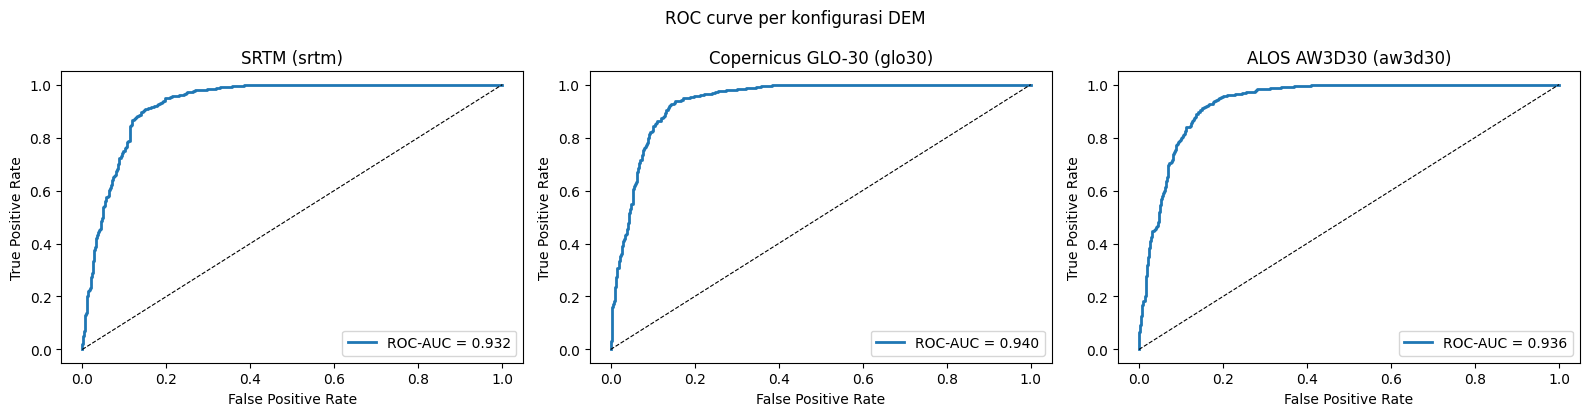

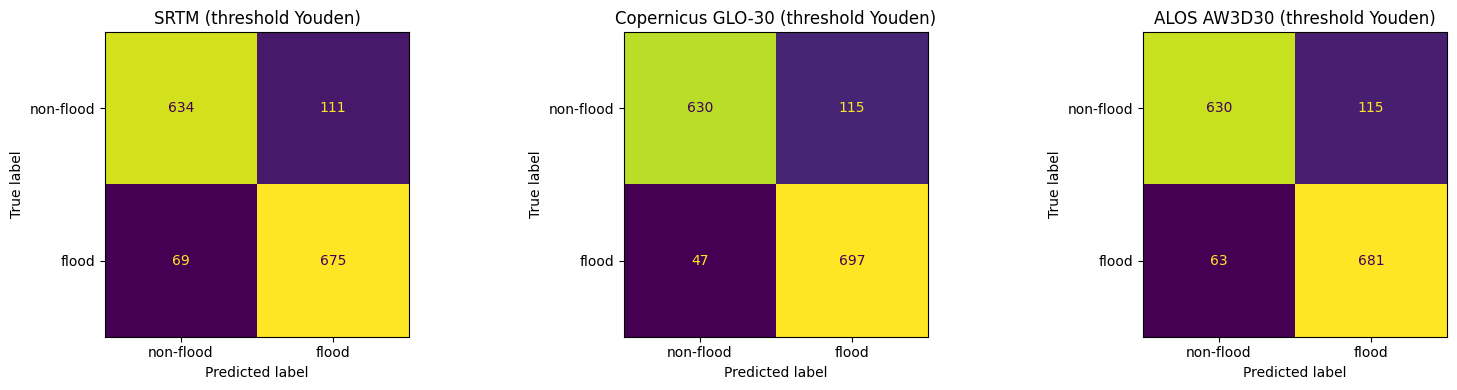

In [15]:
fig, axes = plt.subplots(1, len(results), figsize=(16, 4.2))
for ax, r in zip(np.atleast_1d(axes), results):
    ax.plot(r['fpr'], r['tpr'], lw=2, label=f"ROC-AUC = {r['roc_auc']:.3f}")
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f"{r['label']} ({r['config']})")
    ax.legend(loc='lower right')
fig.suptitle('ROC curve per konfigurasi DEM')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'roc_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, len(results), figsize=(16, 4.0))
for ax, r in zip(np.atleast_1d(axes), results):
    cm = confusion_matrix(r['y_test'], r['y_pred_opt'])
    ConfusionMatrixDisplay(cm, display_labels=['non-flood', 'flood']).plot(ax=ax, colorbar=False)
    ax.set_title(f"{r['label']} (threshold Youden)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrices.png'), dpi=200, bbox_inches='tight')
plt.show()

## 14. Peta probabilitas GEE dan klasifikasi kerawanan

Untuk pemetaan spasial, RF GEE (`ee.Classifier.smileRandomForest`) dilatih per konfigurasi pada sampel yang sama. Peta probabilitas diklasifikasikan menjadi 5 kelas kerawanan dengan **batas kelas yang sama untuk ketiga peta** (default equal interval) agar perbandingan kelas antar-DEM valid.

In [16]:
prob_map = {}
for name in DEM_NAMES:
    input_props = fixed_bands + dem_cols(name)
    clf = (ee.Classifier.smileRandomForest(**RF_GEE)
           .setOutputMode('PROBABILITY')
           .train(
               features=sample_fc,
               classProperty='flood',
               inputProperties=input_props
           ))
    prob_map[name] = (predictor_stack_all.select(input_props)
                      .classify(clf)
                      .rename(f'prob_{name}')
                      .clip(roi))
    print('Peta probabilitas selesai:', name)

if RISK_CLASS_METHOD == 'quantile_reference':
    ref_stats = prob_map['srtm'].reduceRegion(
        reducer=ee.Reducer.percentile([20, 40, 60, 80]),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).getInfo()
    BREAKS = [
        ref_stats['prob_srtm_p20'], ref_stats['prob_srtm_p40'],
        ref_stats['prob_srtm_p60'], ref_stats['prob_srtm_p80']
    ]
else:
    BREAKS = [0.2, 0.4, 0.6, 0.8]

print('Metode klasifikasi:', RISK_CLASS_METHOD)
print('Batas kelas (sama untuk semua peta):', BREAKS)

def classify_risk(pimg):
    return pimg.expression(
        "(p <= b1) ? 1" +
        ": (p <= b2) ? 2" +
        ": (p <= b3) ? 3" +
        ": (p <= b4) ? 4" +
        ": 5",
        {
            'p': pimg,
            'b1': ee.Number(BREAKS[0]),
            'b2': ee.Number(BREAKS[1]),
            'b3': ee.Number(BREAKS[2]),
            'b4': ee.Number(BREAKS[3])
        }
    ).rename('risk_class')

risk_class = {name: classify_risk(prob_map[name]) for name in DEM_NAMES}
print('Klasifikasi kerawanan 5 kelas selesai untuk', list(risk_class.keys()))

Peta probabilitas selesai: srtm
Peta probabilitas selesai: glo30
Peta probabilitas selesai: aw3d30
Metode klasifikasi: equal_interval
Batas kelas (sama untuk semua peta): [0.2, 0.4, 0.6, 0.8]
Klasifikasi kerawanan 5 kelas selesai untuk ['srtm', 'glo30', 'aw3d30']


## 15. Visualisasi peta probabilitas dan kelas kerawanan

In [17]:
Map2 = geemap.Map(center=[MAP_CENTER[0], MAP_CENTER[1]], zoom=MAP_ZOOM)
Map2.add_basemap('HYBRID')
Map2.centerObject(roi, MAP_ZOOM)
# FAULT-TOLERANT v22: lihat catatan cell Map.
try:
    for name in DEM_NAMES:
        lbl = DEM_CONFIGS[name]['label']
        Map2.addLayer(prob_map[name], PROB_VIS, f'Prob {lbl}')
        Map2.addLayer(risk_class[name], RISK_VIS, f'Kelas {lbl}')
except Exception as e:
    print(f'Lapisan peta Map2 dilewati (tile service timeout, hasil tidak terpengaruh): {e}')
safe_add_legend(Map2, 'Kelas kerawanan', risk_legend)
safe_add_layer_control(Map2)

# Bonus: figure statis PNG untuk artikel.
for name in DEM_NAMES:
    save_thumb(prob_map[name], PROB_VIS, roi, f'fig_prob_{name}.png')
    save_thumb(risk_class[name], RISK_VIS, roi, f'fig_risk_{name}.png')
Map2

Thumbnail gagal (percobaan 1/4), coba 1200px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/b526de37fc30fa763576569625f02adb-de8d3f9ac9a126a80a8f5d4bf8b5ffb0:getPixels
Thumbnail gagal (percobaan 2/4), coba 900px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/ae78a8911d5c2ac5cbca6fcf20f1ab69-4c76c2971dbf6f55589f54ef5e648d40:getPixels
Thumbnail gagal (percobaan 3/4), coba 675px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/7b97714dd5aaa5e6dcf85097694e5757-105d241610bbeb48fbb6e79b1e95d8e8:getPixels
Thumbnail gagal (percobaan 4/4), coba 600px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/0266ed9196e96a5fd940e92cac920e26-268cb40faaa529733f16e1476898853d:getPixels
Gagal membuat thumbnail: fig_prob_srtm.png 

Map(center=[-6.9475803324210075, 110.56793539002611], controls=(WidgetControl(options=['position', 'transparen…

## 16. Analisis sensitivitas spasial

Menjawab RM/Tujuan 3: **di mana** dan **seberapa besar** hasil susceptibility berubah ketika sumber DEM diganti.

1. **Peta delta probabilitas** (absolut, pairwise).
2. **Kesesuaian kelas** (spatial agreement) antarproduk.
3. **Matriks perpindahan kelas** (kelas kerawanan produk A -> produk B).
4. **Luas area per kelas** untuk setiap produk.

In [18]:
pairs = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]

delta_abs = {}
agreement_map = {}
for p in pairs:
    a, b = p
    delta_abs[p] = prob_map[a].subtract(prob_map[b]).abs().rename('delta_abs').clip(roi)
    agreement_map[p] = risk_class[a].eq(risk_class[b]).rename('agreement').clip(roi)

# --- Ringkasan keseluruhan ---
summary = []
for p in pairs:
    mean_abs = delta_abs[p].reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).get('delta_abs').getInfo()
    agree = agreement_map[p].reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).get('agreement').getInfo()
    summary.append({
        'pair': f'{p[0]} vs {p[1]}',
        'mean_abs_delta_prob': float(mean_abs) if mean_abs is not None else None,
        'agreement_rate': float(agree) if agree is not None else None,
    })
sensitivity_summary_df = pd.DataFrame(summary)
sensitivity_summary_df.to_csv(os.path.join(OUTPUT_DIR, 'sensitivity_summary.csv'), index=False)
display(sensitivity_summary_df)

# --- Matriks perpindahan kelas ---
transition_matrices = {}
for p in pairs:
    code_img = risk_class[p[0]].multiply(10).add(risk_class[p[1]]).rename('trans')
    hist = code_img.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).get('trans').getInfo()
    mat = pd.DataFrame(0, index=range(1, 6), columns=range(1, 6), dtype='int64')
    for k, v in (hist or {}).items():
        c = int(float(k))
        i, j = c // 10, c % 10
        if 1 <= i <= 5 and 1 <= j <= 5:
            mat.loc[i, j] = int(v)
    transition_matrices[p] = mat
    mat.to_csv(os.path.join(OUTPUT_DIR, f'transition_{p[0]}_vs_{p[1]}.csv'))

transition_matrices[('srtm', 'glo30')]

,pair,mean_abs_delta_prob,agreement_rate
0,srtm vs glo30,0.055535,0.794240
1,srtm vs aw3d30,0.037134,0.839489
2,glo30 vs aw3d30,0.048265,0.813017


,1,2,3,4,5
1,814424,36959,1170,32,0
2,94348,136026,30943,1320,103
3,15632,34358,58691,18839,849
4,2177,5833,17698,56031,25655
5,277,817,2368,12989,102007


In [19]:
# --- Luas area per kelas kerawanan (km^2) per produk ---
area_tables = {}
for name in DEM_NAMES:
    area_img = ee.Image.pixelArea().addBands(risk_class[name])
    res = area_img.reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).getInfo()
    rows = {}
    for g in res.get('groups', []):
        rows[int(g['class'])] = g['sum'] / 1e6
    area_tables[name] = rows

area_df = pd.DataFrame(area_tables)
area_df.index.name = 'risk_class'
area_df.to_csv(os.path.join(OUTPUT_DIR, 'area_per_risk_class_km2.csv'))
display(area_df)

# --- Peta interaktif delta probabilitas dan kesesuaian ---
# FAULT-TOLERANT v22: sel ini IKUT MEMUAT sains (tabel luas area di atas) sehingga
# visualisasi di bawah WAJIB dibungkus try/except. Pelajaran v21: Map3.addLayer ->
# getMapId 'Computation timed out' SETELAH semua sains selesai.
Map3 = None
try:
    Map3 = geemap.Map(center=[MAP_CENTER[0], MAP_CENTER[1]], zoom=MAP_ZOOM)
    Map3.add_basemap('HYBRID')
    Map3.centerObject(roi, MAP_ZOOM)
    for p in pairs:
        Map3.addLayer(delta_abs[p], DELTA_VIS, f'|Delta prob| {p[0]} vs {p[1]}')
        Map3.addLayer(agreement_map[p], {'min': 0, 'max': 1, 'palette': ['#7f0000', '#1a9850']},
                      f'Agreement {p[0]} vs {p[1]}')
    safe_add_layer_control(Map3)
except Exception as e:
    print(f'Peta interaktif Map3 dilewati (tile service timeout, hasil tidak terpengaruh): {e}')

# Bonus: figure statis PNG untuk artikel.
for p in pairs:
    save_thumb(delta_abs[p], DELTA_VIS, roi, f'fig_delta_{p[0]}_vs_{p[1]}.png')
    save_thumb(agreement_map[p], {'min': 0, 'max': 1, 'palette': ['#7f0000', '#1a9850']},
               roi, f'fig_agreement_{p[0]}_vs_{p[1]}.png')
Map3

,srtm,glo30,aw3d30
risk_class,,,
1,756.660841,822.591831,772.538802
2,233.236090,189.964945,222.013706
3,113.957225,98.423942,108.131966
4,95.340180,79.199131,88.237544
5,105.158128,114.172615,113.430446


Thumbnail gagal (percobaan 1/4), coba 1200px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/903eb345ad573dd1d034bb37d71bd990-2e453cc5345c218745a6490d81fa7b0e:getPixels
Thumbnail gagal (percobaan 2/4), coba 900px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/afe275375821450e3af5fac969f61a8a-e08cf44cc2ce087b5eaf7111f42a6826:getPixels
Thumbnail gagal (percobaan 3/4), coba 675px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/54c6d1154b928f5db7d899406e789eba-73d5427c163ef73cba1473f033d33221:getPixels
Thumbnail gagal (percobaan 4/4), coba 600px: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/ee-irfan-banjir-2026/thumbnails/1a2e4b5d2ba28e78fdaeee82b29c5397-33550cb1ef859f89fa03a08f0515ca8b:getPixels
Gagal membuat thumbnail: fig_delta_srtm_vs_

Map(center=[-6.9475803324210075, 110.56793539002611], controls=(WidgetControl(options=['position', 'transparen…

## 17. Stratifikasi berdasarkan tutupan lahan (WorldCover)

Menjawab RM/Tujuan 4: apakah sensitivitas sumber elevasi berbeda antar kelas tutupan lahan? Metrik yang dihitung per kelas WorldCover:

- rata-rata |delta probabilitas|,
- tingkat kesesuaian kelas kerawanan (agreement rate),
- proporsi piksel yang berubah kelas.

,pair,metric,lc_code,lc_name,value
0,srtm vs glo30,mean_abs_delta_prob,10,Tree cover,0.020910
1,srtm vs glo30,mean_abs_delta_prob,20,Shrubland,0.094822
2,srtm vs glo30,mean_abs_delta_prob,30,Grassland,0.053931
3,srtm vs glo30,mean_abs_delta_prob,40,Cropland,0.072709
4,srtm vs glo30,mean_abs_delta_prob,50,Built-up,0.051426
...,...,...,...,...,...
76,glo30 vs aw3d30,prop_class_changed,50,Built-up,0.100113
77,glo30 vs aw3d30,prop_class_changed,60,Bare/sparse vegetation,0.330981
78,glo30 vs aw3d30,prop_class_changed,80,Water,0.216493
79,glo30 vs aw3d30,prop_class_changed,90,Wetland,0.258217


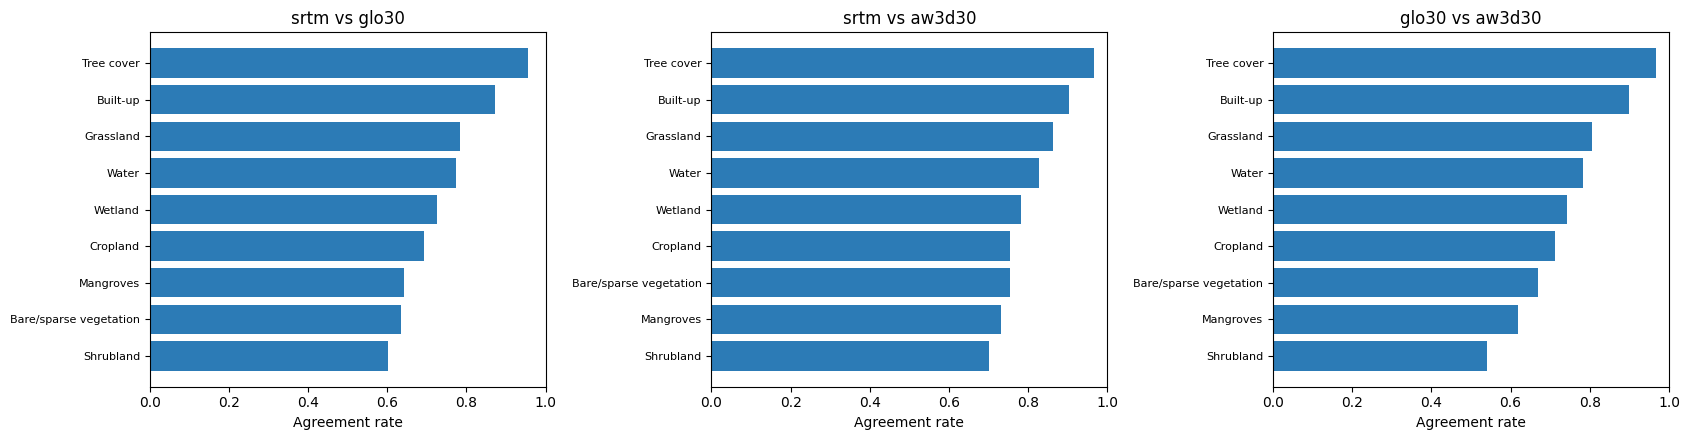

In [20]:
lc_band = landcover.rename('lc')

WORLDCOVER_NAMES = {
    10: 'Tree cover', 20: 'Shrubland', 30: 'Grassland', 40: 'Cropland',
    50: 'Built-up', 60: 'Bare/sparse vegetation', 70: 'Snow/ice', 80: 'Water',
    90: 'Wetland', 95: 'Mangroves', 100: 'Moss/lichen',
}

def grouped_mean_by_lc(img):
    # Rata-rata img per kelas tutupan lahan WorldCover.
    res = (img.rename('v').addBands(lc_band)
           .reduceRegion(
               reducer=ee.Reducer.mean().group(groupField=1, groupName='lc'),
               geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
           ).getInfo())
    out = {}
    for g in res.get('groups', []):
        if g.get('mean') is not None:
            out[int(g['lc'])] = g['mean']
    return out

wc_rows = []
for p in pairs:
    pair_label = f'{p[0]} vs {p[1]}'

    mean_dp = grouped_mean_by_lc(delta_abs[p])
    for lc_code, v in mean_dp.items():
        wc_rows.append({'pair': pair_label, 'metric': 'mean_abs_delta_prob',
                        'lc_code': lc_code, 'lc_name': WORLDCOVER_NAMES.get(lc_code, str(lc_code)),
                        'value': v})

    agree = grouped_mean_by_lc(agreement_map[p])
    for lc_code, v in agree.items():
        wc_rows.append({'pair': pair_label, 'metric': 'agreement_rate',
                        'lc_code': lc_code, 'lc_name': WORLDCOVER_NAMES.get(lc_code, str(lc_code)),
                        'value': v})

    changed = risk_class[p[0]].neq(risk_class[p[1]]).rename('changed')
    prop_changed = grouped_mean_by_lc(changed)
    for lc_code, v in prop_changed.items():
        wc_rows.append({'pair': pair_label, 'metric': 'prop_class_changed',
                        'lc_code': lc_code, 'lc_name': WORLDCOVER_NAMES.get(lc_code, str(lc_code)),
                        'value': v})

worldcover_df = pd.DataFrame(wc_rows)
worldcover_df.to_csv(os.path.join(OUTPUT_DIR, 'worldcover_sensitivity.csv'), index=False)
display(worldcover_df)

# Visualisasi: agreement rate per kelas tutupan lahan.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, p in zip(np.atleast_1d(axes), pairs):
    sub = (worldcover_df[(worldcover_df['pair'] == f'{p[0]} vs {p[1]}') &
                         (worldcover_df['metric'] == 'agreement_rate')]
           .sort_values('value'))
    if len(sub):
        ax.barh(sub['lc_name'], sub['value'], color='#2c7bb6')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Agreement rate')
    ax.set_title(f'{p[0]} vs {p[1]}')
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'agreement_per_landcover.png'), dpi=200, bbox_inches='tight')
plt.show()

## 18. Export peta dan data ke Google Drive

In [21]:
# Guard EXPORT_TO_DRIVE v24 (pelajaran v21: satu task gagal TIDAK boleh
# menghentikan kernel; kegagalan di-log, ekspor lainnya lanjut).
EXPORT_TO_DRIVE = True
DRIVE_FOLDER = 'GEE_DEM_Sensitivity_Semarang_Demak'

def export_image(img, name):
    if not EXPORT_TO_DRIVE:
        print('EXPORT_TO_DRIVE = False - lewati', name)
        return
    try:
        task = ee.batch.Export.image.toDrive(
            image=img.toFloat(),
            description=name,
            folder=DRIVE_FOLDER,
            fileNamePrefix=name,
            region=roi,
            scale=30,
            maxPixels=1e13
        )
        task.start()
        print('Export started:', name)
    except Exception as e:
        print(f'Export GAGAL ({name}): {e}')

if EXPORT_TO_DRIVE:
    # Peta probabilitas, kelas kerawanan, delta, dan kesesuaian.
    for name in DEM_NAMES:
        export_image(prob_map[name], f'prob_{name}')
        export_image(risk_class[name], f'risk_class_{name}')
    for p in pairs:
        export_image(delta_abs[p], f'delta_abs_{p[0]}_vs_{p[1]}')
        export_image(agreement_map[p], f'agreement_{p[0]}_vs_{p[1]}')

    # Label banjir dan sampel training.
    export_image(flood_label.toByte(), 'proxy_flood_label_sentinel1')
    try:
        task_table = ee.batch.Export.table.toDrive(
            collection=sample_fc,
            description='training_sample_dem_sensitivity',
            folder=DRIVE_FOLDER,
            fileNamePrefix='training_sample_dem_sensitivity',
            fileFormat='CSV'
        )
        task_table.start()
        print('Export started: training_sample_dem_sensitivity (CSV)')
    except Exception as e:
        print(f'Export tabel sampel GAGAL: {e}')
else:
    print('EXPORT_TO_DRIVE = False. Ubah menjadi True jika ingin export ke Google Drive.')
print('Catatan: CSV metrik/sensitivitas sudah tersimpan di OUTPUT_DIR:', OUTPUT_DIR)


Export started: prob_srtm
Export started: risk_class_srtm
Export started: prob_glo30
Export started: risk_class_glo30
Export started: prob_aw3d30
Export started: risk_class_aw3d30
Export started: delta_abs_srtm_vs_glo30
Export started: agreement_srtm_vs_glo30
Export started: delta_abs_srtm_vs_aw3d30
Export started: agreement_srtm_vs_aw3d30
Export started: delta_abs_glo30_vs_aw3d30
Export started: agreement_glo30_vs_aw3d30
Export started: proxy_flood_label_sentinel1
Export started: training_sample_dem_sensitivity (CSV)
Catatan: CSV metrik/sensitivitas sudah tersimpan di OUTPUT_DIR: outputs_dem_sensitivity


## 19. Metodologi utama

1. **Flood inventory (dikunci).** Label banjir dibentuk satu kali dari perubahan *backscatter* Sentinel-1 SAR pra/pasca kejadian (Maret 2024), dengan masking air permanen JRC dan filter noise *connected pixels*. Label ini dipakai identik pada ketiga eksperimen.
2. **Faktor perlakuan.** Satu-satunya komponen yang berubah adalah sumber produk elevasi: SRTM, Copernicus DEM GLO-30, dan ALOS AW3D30. Dari masing-masing dihitung elevasi, slope, dan aspect dengan prosedur identik (`ee.Terrain`), termasuk penanganan void mask AW3D30 dan pelaporan offset vertikal EGM96/EGM2008.
3. **Prediktor non-DEM (dikunci).** HAND, log-upstream area, river width, jarak sungai, jarak air permanen, curah hujan antecedent 7/30 hari, NDVI, NDWI, MNDWI, NDBI, dan tutupan lahan — mengikuti set baseline artikel SMDS.
4. **Sampling dan split (dikunci).** Stratified sampling satu kali dari gabungan semua band dengan seed tetap; titik dan jumlah sampel identik untuk ketiga konfigurasi. Train/test split memakai seed sama sehingga data uji identik.
5. **Random Forest (dikunci).** Evaluasi memakai sklearn (400 pohon, min samples leaf 2, class weight balanced); pemetaan spasial memakai `ee.Classifier.smileRandomForest` (300 pohon) pada sampel yang sama.
6. **Evaluasi.** ROC-AUC, accuracy, precision, recall, F1 pada data uji identik; ambang klasifikasi via indeks Youden. Sensitivitas performa = delta metrik antarproduk.
7. **Sensitivitas spasial.** Peta |delta probabilitas| pairwise, tingkat kesesuaian kelas, matriks perpindahan kelas, dan luas area per kelas.
8. **Stratifikasi WorldCover.** Seluruh metrik sensitivitas dihitung ulang per kelas tutupan lahan untuk menguji apakah sensitivitas sumber elevasi berbeda antar jenis permukaan.

## 20. Batasan penelitian

1. Label banjir berasal dari deteksi Sentinel-1 (*proxy label*), bukan validasi lapangan; galat deteksi SAR pada area urban padat, vegetasi rapat, dan tambak dapat terjadi.
2. Masking slope pada pembentukan label mengikuti baseline (SRTM). Karena inventory harus identik, keputusan ini diterapkan sama untuk semua konfigurasi.
3. SRTM memakai acuan EGM96 sedangkan Copernicus/AW3D30 memakai EGM2008; offset rata-rata dilaporkan (koreksi opsional). Ketiga produk bukan *bare-earth* DTM murni — SRTM adalah DEM radar pita-C, Copernicus GLO-30 dan AW3D30 adalah DSM.
4. Hasil sensitivitas bersifat konteks-spesifik: satu wilayah, satu kejadian banjir, dan satu set prediktor baseline.
5. Interpretasi kelas kerawanan bergantung pada batas klasifikasi; batas kelas yang sama dipakai untuk ketiga peta agar perbandingan valid.
6. Output berupa kerawanan (susceptibility), bukan prediksi genangan real-time.